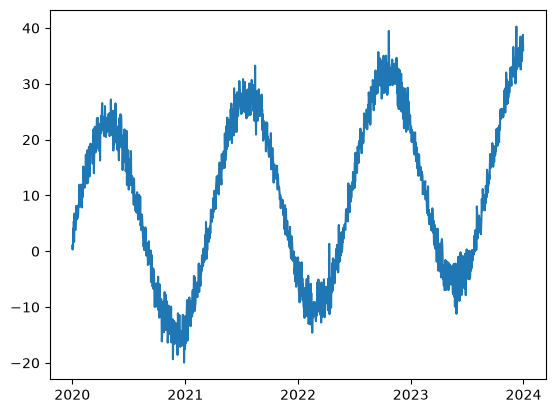

In [11]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

years = int(input("How many years is the time series of? "))

start = pd.Timestamp("2020-01-01")
end = start + pd.DateOffset(years=years) - pd.Timedelta(days=1)

dates = pd.date_range(start, end, freq="D")   # handles leap years for you
num_days = len(dates)
t = np.arange(num_days) 

a_raw = np.sin(t / 72)
short_noise = np.random.poisson(2, num_days)
t_scal = t / 100
a_scal = np.random.normal(20, 2, num_days)
a = a_scal * a_raw + t_scal + short_noise

fig, ax = plt.subplots()
ax.plot(dates, a)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.show()

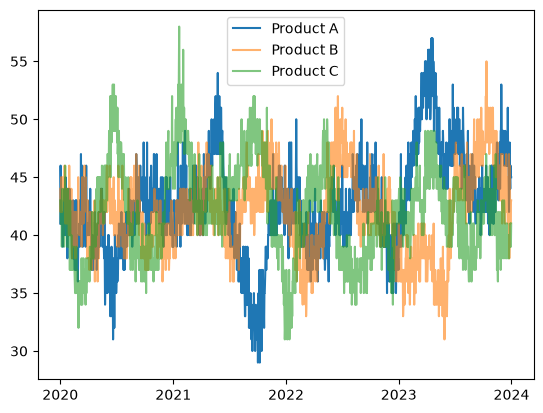

In [63]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import pandas as pd


def ar1_noise(n, phi=0.99, sigma=1.0):
    """Slowly wandering noise. phi near 1 = slower drift."""
    noise = np.zeros(n)
    kicks = np.random.normal(0, sigma, n)
    for i in range(1, n):
        noise[i] = phi * noise[i - 1] + kicks[i]
    return noise

years = int(input("How many years is the time series of? "))

start = pd.Timestamp("2020-01-01")
end = start + pd.DateOffset(years=years) - pd.Timedelta(days=1)
dates = pd.date_range(start, end, freq="D")
num_days = len(dates)
t = np.arange(num_days)

#Basic sine curve
a_raw = np.sin(t / 36)
b_raw = np.cos(t / 36)
c_raw = np.sin(t / 36 + np.pi)

# Day-to-day noise (equivalent to previosu a_scal)
a_short_noise = np.random.poisson(2, num_days)
b_short_noise = np.random.poisson(2, num_days)
c_short_noise = np.random.poisson(2, num_days)
a_amp_daily = np.random.normal(3, 1, num_days)
b_amp_daily = np.random.normal(3, 1, num_days)
c_amp_daily = np.random.normal(3, 1, num_days)

# Long-term randomness
a_amp_drift = ar1_noise(num_days, phi=0.99, sigma=0.4)      # peaks vary in height
a_baseline_drift = ar1_noise(num_days, phi=0.995, sigma=0.3) # slow wandering offset

b_amp_drift = ar1_noise(num_days, phi=0.99, sigma=0.4)      
b_baseline_drift = ar1_noise(num_days, phi=0.995, sigma=0.3)

c_amp_drift = ar1_noise(num_days, phi=0.99, sigma=0.4)     
c_baseline_drift = ar1_noise(num_days, phi=0.995, sigma=0.3)

a = (a_amp_daily + a_amp_drift) * a_raw + a_baseline_drift + a_short_noise + 40
b = (b_amp_daily + b_amp_drift) * b_raw + b_baseline_drift + b_short_noise + 40
c = (c_amp_daily + c_amp_drift) * c_raw + c_baseline_drift + c_short_noise + 40
a = np.round(a)
b = np.round(b)
c = np.round(c)

fig, ax = plt.subplots()
ax.plot(dates, a, label="Product A")
ax.plot(dates, b, label ="Product B",alpha = 0.6)
ax.plot(dates, c, label="Product C", alpha= 0.6)
ax.legend()
#ax.set_ylim(0, 250)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

In [39]:
print(a[300])
np.shape(a)

115.0


(1461,)

In [64]:
import pandas as pd

data = np.column_stack((a,b,c))
#print(data)
np.shape(data)
df = pd.DataFrame({
    "date": dates,
    "Product_A": a,
    "Product_B": b,
    "Product_C": c,
})
df.to_csv("Depot_sales.csv", index=False)

In [ ]:
def make_series(t, level=100, amp=20, phase=0.0):
    n = len(t)
    sine = np.sin(t / 72 + phase)

    amp_daily = np.random.normal(0, 2, n)                      # day-to-day amplitude jitter
    amp_drift = ar1_noise(n, phi=0.99, sigma=0.5)              # peaks vary in height
    baseline_drift = ar1_noise(n, phi=0.995, sigma=0.3)        # slow wandering offset
    short_noise = np.random.poisson(2, n)                      # day-to-day noise

    series = level + (amp + amp_daily + amp_drift) * sine + baseline_drift + short_noise
    return np.maximum(np.round(series), 1)                     # safety net: never below 1

a = make_series(t, level=100, amp=20, phase=0)
b = make_series(t, level=100, amp=20, phase=np.pi / 2)         # cos
c = make_series(t, level=100, amp=20, phase=np.pi)